In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns;sns.set()
from scipy.stats import mode
import scipy.cluster.hierarchy as shc
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import KMeans
from sklearn.datasets import load_digits
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import pairwise_distances_argmin
from sklearn.model_selection import train_test_split

# hierarchical clustering
The kmeans algorithm works very well when we know beforehand how many clusters we expect to find.When we dont...we have to fit several kmeans models with different k values and compare them with the help of elbow methods.

Hierarchical clustering takes a different approach:
- it builds the clusters for every possible number of clusters in a single run.

- kMeans
    - number of cluster chosen before fitting
    - result one grouping into k clusters
    - randomness depends on the random stating centers
    - speed fast also on large dataset
    - new observations= predict() assign them to the nearest center

- hierarchical clustering
    - number of cluster chosen after fitting by cutting the tree
    - result a full hierarchy(tree) of clusters
    - randomness deterministic...same result on every run
    - speed slow on large dataset
    - new observations= no predict in sklearn

We dont need to specify the number of clusters upfront.we get hierarchy that we can cut at any level to obtain the number of froups we want

- in total hierarchical clustering is ml algorithm that groups similar datapoints into cluster by creating a hierchy(tree based structure) of cluster

there are two approach
- agglomerative(bottom up)= start with individual datapoints and gradually combine them
- divisive(top down)=start with one big cluster and gradually split it

example of agglomerative cluster(Continues calculating distance in each clusters till it merges)
- imagine there are 6 customer...intitaly it hit every customr to each cluster like cluster 1,2,3,4,5,6...now we have 6 clusters...and then the algorithm start calculating the distance of each data points and check which one are closely similar..for example 1 and 2,3 and 4,5 and 6 are very similar to each other...the it mergers the clusters together...cluster a(1,2),cluster b(3,4),cluster c(5,6)..and then it continues  calculating distances in one big clusters 

the flow is start-measure-merge-repeat

# problem setting
We continue with the handwritten digits dataset from the old chapters...without using labels to build the model...it will allow us ti compare hierarchical clustering with k means

In [2]:
digits = load_digits()
digits.data.shape

(1797, 64)

The result of  clusters is a hierarchy that contains a solution for every possible number of clusters,from n down to 1.We visualize it with a dendrogram, a treee diagram in which the height of each horizontal line shows the distance at which two clusters were merged.To get the clusters, we cut the dendrogram with a horizontal line ,every vertical line that the cut crosses become one cluster.

- high cut=Fewer,larger clusters
- low cut= more,smaller clusters

a good placce to cut is where the vertical lines are longest.There, the clusters stay separate over a long distance before the merge,which points to a natural separation in the data

- Linkage:How to measure the distance between two clusters?..step 2 needs the distance between two clusters,not just between two points.The linkage method defines the distance:

| Linkage | Distance between two clusters | Typical behavior |
|---|---|---|
| **Ward** (most common) | How much the within-cluster variance increases when they merge | Compact, round clusters of similar size, like k-Means |
| **Complete** | The *maximum* distance between their members | Compact clusters, but sensitive to outliers |
| **Average** | The *average* distance between all pairs of members | A compromise between complete and single |
| **Single** | The *minimum* distance between their members | Can follow long, irregular shapes, but tends to "chain" almost everything into one big cluster |

# Model estimation
Lets create a dendrogram of the digits dataset.The function shc.linkage() performs all merges and returns the linkage mattrix Z.Every row of z describes one merge

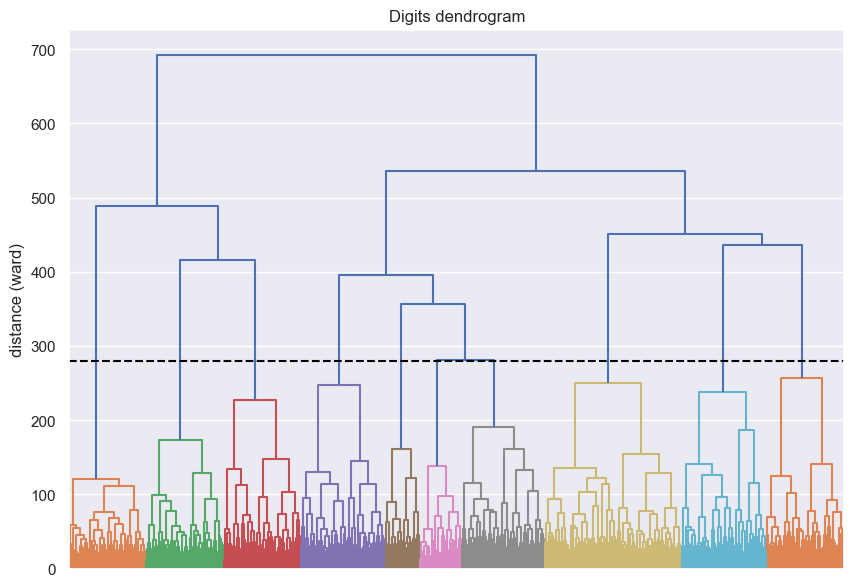

In [3]:
# linkage() performs all merges,every row of z describes one merge
Z = shc.linkage(digits.data,method='ward')
plt.figure(figsize=(10,7))
plt.title('Digits dendrogram')
dend = shc.dendrogram(Z,color_threshold=280,no_labels=True)
plt.axhline(y=280,color='Black',linestyle='--')
plt.ylabel('distance (ward)')
plt.show()

interpreting the dendrogram:
- the dashed line at a height of 280 crosses 10 vertical lines, so it splits the images into 10 cluster, shown in different colors below the line
- since we know there are 10 different digits, we fit out model with 10 clusters.
- this is not necessarily the most natural cut.

the higher the horizontal connection,The greater the ward distance associated with the merge.

In [ ]:
cluster = AgglomerativeClustering(n_clusters=10,linkage='ward') 
clusters = cluster.fit_predict(digits.data)
print('number of images in each cluster:',np.bincount(clusters))

number of images in each cluster: [181 317 197 196 191 178 181 178  80  98]


According to the output...
- cluster 0 has 181 images
- cluster 1 has 317 images
- cluster 2 has 197 images
- cluster 3 has 196 images
- cluster 4 has 191 images
and so on..

For kMeans we used the inertia to create the elbow plot.Hierarchical clustering doesnt use centroids,So we have to use the merge height z[:,2]
instead: the distance between the two clusters at the moment they merge.
The last row z in the final merge (2 cluster-1),the row before it merges 3 clusters-2..so if we take the last 32 merge heights and reverse them,The value at position k is the height of the merge that turns k+1 cluster into k

- a large drop between k-1 and k means that the k clusters are far apart from each other: a natural place to cut.

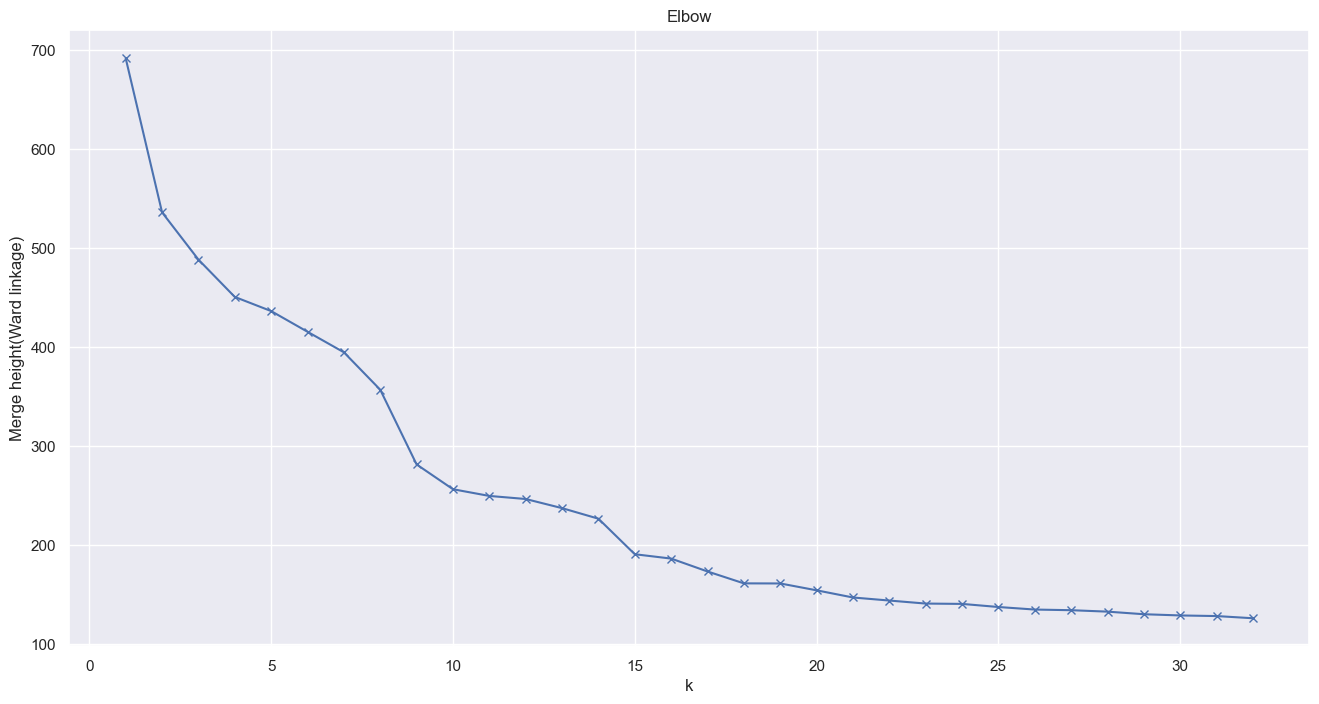

In [ ]:
# elbow method: Take the last 32 merge heights and reverse them to match the increasing number of clusters
last = Z[-32:,2] #last 32 rows and column 3..cuz the merge heights stores height from earliest to latest and 3 column is the merge heights..so we need lastest marge heights
last_rev = last[::-1] # reversing the merge heights
plt.figure(figsize=(16,8))
plt.plot(range(1,33),last_rev,'bx-')
plt.xlabel('k')
plt.ylabel('Merge height(Ward linkage)')
plt.title('Elbow')
plt.show()

The elbow is hard to read by eye,So lets calculate it,To get k clusters, we must cut between the merge that creates k clusters and the merge that creates k-1 clusters.The bigger this gap,the more natural the cut:

In [6]:
# all merge heights from high to low: heights[0] is the final merge(2 clusters -> 1)
heights = Z[::-1,2]
# the get k clusters, we cut somewhere between heights [k-1](lower) and heights[k-2] (upper)
gaps = pd.DataFrame({'k': range(2,16),'cut from':heights[1:15],'cut to':heights[0:14]})
gaps['gap'] = gaps['cut to']-gaps['cut from']
gaps.sort_values('gap',ascending=False).head(7).round(1)

,k,cut from,cut to,gap
0,2,536.3,692.0,155.6
7,9,281.7,357.2,75.5
1,3,488.6,536.3,47.7
6,8,357.2,395.0,37.8
2,4,450.9,488.6,37.7
13,15,191.0,226.9,35.9
8,10,256.7,281.7,25.0


# analyzing the elbow plot
| k | Gap | Interpretation |
|---|---|---|
| 2 | 155.6 | The largest gap, but 2 clusters is far too few for 10 digits |
| **9** | **75.5** | The clearest elbow after k = 2 |
| 10 | 25.0 | A reasonable choice, but a much weaker elbow than 9 |

- the curve drops much more irregulary than the kMeans elbow plots: each point is one single merge
- The data itself points to **9 clusters** rather than 10. In the dendrogram, a cut gives 9 clusters anywhere between a height of 282 and 357, but 10 clusters only between 257 and 282.
- What does that 10th split do? With 9 clusters, one cluster contains both 167 eights and 96 ones. Going to 10 clusters splits it into an almost pure cluster of 8s and a pure cluster of 1s. So for recognizing digits, **10 clusters is the better choice**, even though 9 is the more natural cut.
- In both cases, the 3s and the 9s stay together in one cluster (169 threes and 145 nines): in pixel space, these digits are simply too close.

Unlike KMeans, AgglomerativeClustering has no predict() method: it can only cluster the images it was fitted on. To evaluate the model on test images it has never seen, we do what k-Means does in its predict(), and assign each new image to the nearest cluster center:

| Step | Action | Uses labels? |
|---|---|---|
| 1 | Fit hierarchical clustering on the training images | No |
| 2 | Translate each cluster into its most common digit | Training labels only |
| 3 | Calculate the center (mean image) of each training cluster | No |
| 4 | Assign each test image to the nearest center and look up the digit of that cluster | No |
| 5 | Compare the predictions with the true test labels | Test labels, only to evaluate |

To find the *best possible* model, we repeat this for all four linkage methods.

In [ ]:
x_train,x_test,y_train,y_test = train_test_split(digits.data,digits.target,test_size=0.25,random_state=0)

def evaluate_hierarchical(linkage):
    #fitting hierarchical clustering on the training image only
    train_cluster=AgglomerativeClustering(n_clusters=10,linkage=linkage).fit_predict(x_train)
    #translating each cluster into its most common digit,using the training labels only
    cluster_to_digit = []
    for i in range(10):
        cluster_to_digit.append(mode(y_train[train_cluster==i])[0])
    cluster_to_digit = np.array(cluster_to_digit)
    # the center of each cluster is the mean of its training images
    centers = []
    for i in range(10):
        centers.append(x_train[train_cluster==i].mean(axis=0))
    centers = np.array(centers)
    # assign each test image to its nearest center and look up the digit of that cluster
    test_clusters = pairwise_distances_argmin(x_test,centers)
    train_prediction = cluster_to_digit[train_cluster]
    test_prediction = cluster_to_digit[test_clusters]
    return train_cluster,train_prediction,test_prediction
result=[]
for linkage in ['ward','complete','average','single']:
    train_clusters,train_prediction,test_prediction=evaluate_hierarchical(linkage)
    result.append({"linkage":linkage,"train_accuracy":accuracy_score(y_train,train_prediction),"test_accuracy":accuracy_score(y_test,test_prediction),'largest cluster':np.bincount(train_clusters).max()})
pd.DataFrame(result).round(3)

,linkage,train_accuracy,test_accuracy,largest cluster
0,ward,0.812,0.776,280
1,complete,0.679,0.729,247
2,average,0.704,0.651,272
3,single,0.114,0.131,1337


- comparing the linkage methods

| Linkage | Test accuracy | Verdict |
|---|---|---|
| **Ward** | **77.6%** | Best model: compact clusters suit the digits |
| Complete | 72.9% | Decent, but clearly worse |
| Average | 65.1% | Several clusters are labeled with the same digit |
| Single | 13.1% | Chaining: one cluster contains 1,337 of the 1,347 training images |

- ward training accuracy and test accuracy are close: the model generalizes well to unseen images
- complete linkage scores higher on the tst set than on the training set.

# errors of the best model

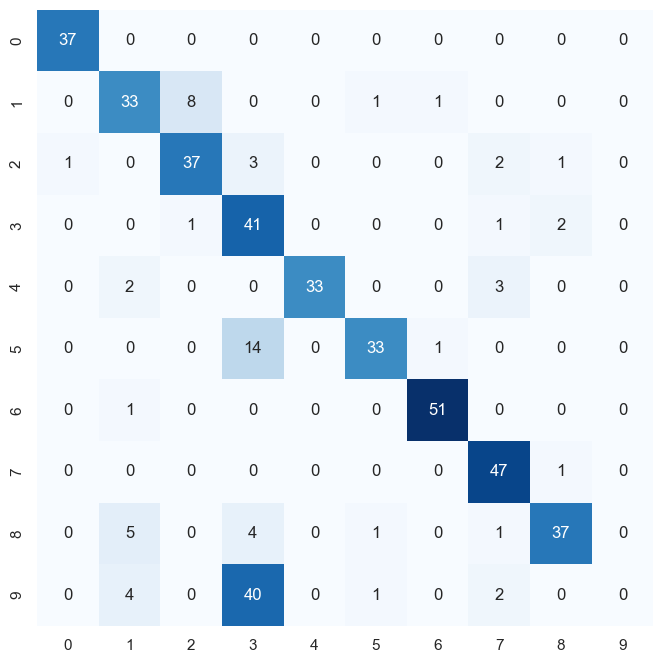

In [12]:
train_clusters,train_prediction,test_prediction = evaluate_hierarchical('ward')
cm = confusion_matrix(y_test,test_prediction)
plt.figure(figsize=(8,8))
sns.heatmap(cm,square=True,annot=True,fmt='d',cbar=False,cmap='Blues',xticklabels=digits.target_names,yticklabels=digits.target_names)
plt.show()

**Model performance:**

We reach an accuracy of about **78%** on the test set. That's impressive, considering that:

- The model never saw the true labels while forming the clusters (only to name them afterwards)
- The test images played no role at all in building the model
- Random guessing would only give 10%

The most common mistakes:

| True digit | Predicted as | Count | Why? |
|---|---|---|---|
| 9 | 3 | 40 of 47 | No cluster is labeled as a 9: two clusters are labeled as a 1 instead |
| 5 | 3 | 14 of 48 | Both digits have a curve in the lower half |
| 1 | 2 | 8 of 43 | Some 1s are written with a base line at the bottom |

These are the same kind of errors that k-Means made in the previous chapter: some digits are so close in pixel space that they don't get a cluster of their own.

For a fair comparison, we evaluate both models in exactly the same way:

- Full dataset: cluster all 1,797 images and name each cluster after its most common digit (as in chapter 7 and section 8.3.2)
- Train/test: the approach from Question 2, on the same split as chapter 7

In [14]:
def cluster_accuracy(clusters, y):
    # Name each cluster after its most common digit and calculate the accuracy
    labels = np.zeros_like(clusters)
    for i in range(10):
        mask = (clusters == i)
        labels[mask] = mode(y[mask])[0]
    return accuracy_score(y, labels)

# Full dataset
hc_full = cluster_accuracy(AgglomerativeClustering(n_clusters=10, linkage='ward').fit_predict(digits.data), digits.target)
km_full = cluster_accuracy(KMeans(n_clusters=10, n_init=10, random_state=0).fit_predict(digits.data), digits.target)

# Train/test: hierarchical clustering with the function from Question 2
_, hc_train_predictions, hc_test_predictions = evaluate_hierarchical('ward')

# Train/test: k-Means can use its own predict() method
kmeans = KMeans(n_clusters=10, n_init=10, random_state=0)
km_train_clusters = kmeans.fit_predict(x_train)
km_cluster_to_digit = np.array([mode(y_train[km_train_clusters == i])[0] for i in range(10)])
km_train_predictions = km_cluster_to_digit[km_train_clusters]
km_test_predictions = km_cluster_to_digit[kmeans.predict(x_test)]

comparison = pd.DataFrame({
    'full dataset': [hc_full, km_full],
    'train accuracy': [accuracy_score(y_train, hc_train_predictions), accuracy_score(y_train, km_train_predictions)],
    'test accuracy': [accuracy_score(y_test, hc_test_predictions), accuracy_score(y_test, km_test_predictions)]
}, index=['Hierarchical (Ward)', 'k-Means'])
comparison.round(3)

,full dataset,train accuracy,test accuracy
Hierarchical (Ward),0.862,0.812,0.776
k-Means,0.792,0.797,0.784


**Comparative analysis:**

| | Hierarchical (Ward) | k-Means | Winner |
|---|---|---|---|
| Full dataset | **86.2%** | 79.2% | Hierarchical (+7 percentage points) |
| Test set | 77.6% | **78.4%** | A tie (less than 1 point difference) |

**Which one provides the best fit?** As a *clustering* of the data, hierarchical clustering clearly wins: its 10 clusters match the true digits much better than the k-Means clusters. On the full dataset, its biggest mistake is merging the 9s with the 3s. k-Means makes more mistakes: no cluster is labeled as an 8, and many 5s and 8s end up in the cluster of the 9s.

**But on unseen images, the advantage disappears.** To predict a test image, we reduce every cluster to one center and assign the image to the nearest one. That is exactly how k-Means works, so in this step we actually turn our hierarchical model into a k-Means-like model.